# PA 766 Module 9

**Question:** How did Proposition 99 affect cigarette sales in California?

By the end, you should be able to run a synthetic control analysis, explain its
counterfactual, quantify the estimated effect, and assess the evidence behind a
causal interpretation. We will follow one example all the way through.

## 1. The policy, outcome, and comparison

California voters passed Proposition 99 in November 1988. It took effect in
January 1989 and combined a cigarette-tax increase with tobacco-control activities.
We estimate the effect of this policy package on **annual cigarette sales, in packs
per person**. Sales are a proxy for consumption; they do not measure the percentage
of residents who smoke.

| Study choice | This analysis |
|:--|:--|
| Treated unit | California |
| First treated year | 1989 |
| Pre-treatment period used for fitting | 1970–1988, 19 years |
| Post-treatment period used for reporting | 1989–2000, 12 years |
| Donor pool | 38 other states in the supplied dataset |
| Counterfactual | California's cigarette sales if Proposition 99 had not occurred |

The data follow the study by [Abadie, Diamond, and Hainmueller (2010)](https://www.mit.edu/~jhainm/Paper/ccs.pdf).
Its donor pool excludes states with major tobacco-control programs or large
cigarette-tax increases during the study period, as well as Washington, DC.
This curated set of states is already in the supplied CSV.

**The key comparison:** California after 1989 versus synthetic California in those
same years. A decline within California alone does not establish a policy effect:
cigarette sales could have fallen even without Proposition 99.

## 2. Setup and data

We use the classic SCM implementation in [pysyncon](https://sdfordham.github.io/pysyncon/).
The model specification is explicit below. This classroom analysis need not
reproduce every published weight or the previous notebook's penalized estimates.

In [4]:
%pip install -q pysyncon==1.7.0 numpy==1.26.4 scipy==1.13.1 pandas==2.2.3 matplotlib==3.10.3 contourpy==1.3.2

In [1]:
from pathlib import Path
from importlib.metadata import version
from time import perf_counter
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pysyncon import Dataprep, Synth

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 120,
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
})
BLUE, ORANGE, GRAY = "#175A8C", "#C66522", "#8B9298"
pd.set_option("display.max_columns", 10)

print("Python", sys.version.split()[0])
print(" | ".join(f"{p} {version(p)}" for p in
                 ["pysyncon", "numpy", "scipy", "pandas", "matplotlib"]))

Python 3.13.18
pysyncon 1.7.0 | numpy 1.26.4 | scipy 1.13.1 | pandas 2.2.3 | matplotlib 3.10.3


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Change DATA_FILE only if you keep the CSV somewhere else.
DATA_FILE = Path("/content/drive/MyDrive/a-ncsu-courses/PA766-2026/Data/Proposition99/proposal99.csv")

csv_path = Path(DATA_FILE)

data = pd.read_csv(csv_path)
required = ["state", "year", "cigsale", "lnincome", "retprice", "age15to24", "beer"]
assert set(required).issubset(data.columns), "This is not the expected Proposition 99 file."
data = data[required].copy()
assert data["year"].notna().all() and (data["year"] % 1 == 0).all()
data["year"] = data["year"].astype(int)
data = data.sort_values(["state", "year"]).reset_index(drop=True)
display(data.head())

,state,year,cigsale,lnincome,retprice,age15to24,beer
0,Alabama,1970,89.8,NaN,39.6,0.178862,NaN
1,Alabama,1971,95.4,NaN,42.7,0.179928,NaN
2,Alabama,1972,101.1,9.498476,42.3,0.180994,NaN
3,Alabama,1973,102.9,9.550107,42.1,0.182060,NaN
4,Alabama,1974,108.2,9.537163,43.1,0.183126,NaN


In [7]:
data

,state,year,cigsale,lnincome,retprice,age15to24,beer
0,Alabama,1970,89.8,NaN,39.6,0.178862,NaN
1,Alabama,1971,95.4,NaN,42.7,0.179928,NaN
2,Alabama,1972,101.1,9.498476,42.3,0.180994,NaN
3,Alabama,1973,102.9,9.550107,42.1,0.182060,NaN
4,Alabama,1974,108.2,9.537163,43.1,0.183126,NaN
...,...,...,...,...,...,...,...
1204,Wyoming,1996,110.3,10.016768,162.5,NaN,24.6
1205,Wyoming,1997,108.8,10.025613,164.1,NaN,24.6
1206,Wyoming,1998,102.9,NaN,168.8,NaN,NaN
1207,Wyoming,1999,104.8,NaN,189.6,NaN,NaN


In [6]:
data.isna().sum()

,0
state,0
year,0
cigsale,0
lnincome,195
retprice,0
age15to24,390
beer,663


In [4]:
# Set the design before looking at the post-treatment estimates.
TREATED = "California"
TREATMENT_YEAR = 1989
PRE_YEARS = list(range(1970, TREATMENT_YEAR))
POST_YEARS = list(range(TREATMENT_YEAR, 2001))
ALL_YEARS = PRE_YEARS + POST_YEARS
DONORS = sorted(set(data["state"]) - {TREATED})
FIT_MULTIPLE = 5  # Pre-specified display rule for comparable placebo fits.

# Check the actual predictor windows; do not drop every row with any missing value.
predictor_windows = {
    "lnincome": list(range(1980, 1989)),
    "retprice": list(range(1980, 1989)),
    "age15to24": list(range(1980, 1989)),
    "beer": list(range(1984, 1989)),
}
for variable, years in predictor_windows.items():
    assert np.isfinite(data.loc[data["year"].isin(years), variable]).all(), variable

outcomes = data.pivot(index="year", columns="state", values="cigsale").loc[ALL_YEARS]
print(f"Checked: {len(data):,} rows; 39 states; {len(PRE_YEARS)} pre-policy years; "
      f"{len(POST_YEARS)} post-policy years.")
print("All outcome values and the predictor values used for fitting are present.")

Checked: 1,209 rows; 39 states; 19 pre-policy years; 12 post-policy years.
All outcome values and the predictor values used for fitting are present.


**Explain 1 — Define the design.** In two sentences, identify the treated unit,
outcome and its units, treatment year, and counterfactual. Why might comparing
California in 2000 with California in 1988 give a misleading policy estimate?

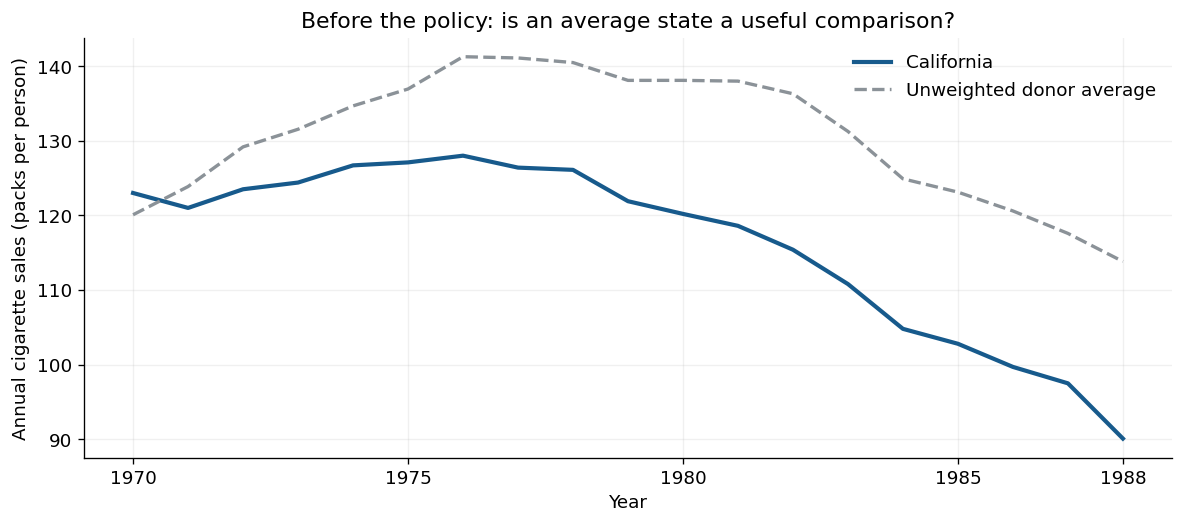

In [5]:
# First inspect only pre-policy data.
fig, ax = plt.subplots()
ax.plot(PRE_YEARS, outcomes.loc[PRE_YEARS, TREATED], color=BLUE, lw=2.5, label="California")
ax.plot(PRE_YEARS, outcomes.loc[PRE_YEARS, DONORS].mean(axis=1),
        color=GRAY, ls="--", lw=2, label="Unweighted donor average")
ax.set(title="Before the policy: is an average state a useful comparison?",
       xlabel="Year", ylabel="Annual cigarette sales (packs per person)")
ax.set_xticks([1970, 1975, 1980, 1985, 1988])
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Fit synthetic California using pre-policy information

A synthetic control is a **weighted average of donor states**. Each weight is
nonnegative, and the weights sum to one. We choose the weights using information
from before 1989, then keep them fixed when constructing the later counterfactual.

| Input used for matching | Pre-policy measurement |
|:--|:--|
| Log income per person (`lnincome`) | Average, 1980–1988 |
| Retail cigarette price (`retprice`, cents per pack) | Average, 1980–1988 |
| Population share aged 15–24 (`age15to24`) | Average, 1980–1988 |
| Beer consumption (`beer`, gallons per person) | Average, 1984–1988 |
| Cigarette sales (`cigsale`) | Separate values for 1975, 1980, and 1988 |

The population share is a fraction: 0.17 means 17%. Log income is reported on
the log scale, so a difference in that row is not a dollar difference.

The package also uses the **full 1970–1988 cigarette-sales path** to choose the
relative emphasis placed on matching these predictors. Predictor importance and
donor weights are different: donor weights tell us which states make up synthetic
California. Neither is a regression coefficient measuring a predictor's causal effect.

The first function defines the study. The second tries two deterministic starting
values and keeps the fit with the smaller pre-treatment prediction error. We reuse
both functions unchanged for the later checks. No post-1988 outcome enters fitting.

In [8]:
def make_dataprep(treated, donors):
    return Dataprep(
        foo=data,
        predictors=["lnincome", "retprice", "age15to24"],
        predictors_op="mean",
        dependent="cigsale",
        unit_variable="state",
        time_variable="year",
        treatment_identifier=treated,
        controls_identifier=list(donors),
        time_predictors_prior=range(1980, 1989),
        time_optimize_ssr=PRE_YEARS,
        special_predictors=[
            ("beer", range(1984, 1989), "mean"),
            ("cigsale", [1975], "mean"),
            ("cigsale", [1980], "mean"),
            ("cigsale", [1988], "mean"),
        ],
    )

def fit_scm(dataprep):
    candidates = []
    for start in ["equal", "ols"]:
        model = Synth()
        model.fit(dataprep=dataprep, optim_method="Powell", optim_initial=start,
                  optim_options={"maxiter": 100, "ftol": 1e-5, "xtol": 1e-4})
        assert np.isfinite(model.W).all() and np.isfinite(model.mspe())
        assert model.W.min() >= -1e-7 and np.isclose(model.W.sum(), 1, atol=1e-6)
        candidates.append(model)
    return min(candidates, key=lambda model: model.mspe())

dataprep = make_dataprep(TREATED, DONORS)
sc = fit_scm(dataprep)
print("Synthetic California fitted using pre-treatment data.")

Synthetic California fitted using pre-treatment data.


In [14]:
# Keep full precision for calculation. Round only the displayed table.
weights = pd.Series(sc.W, index=sc.W_names, name="weight")
weight_table = weights.sort_values(ascending=False).to_frame()
weight_table["weight_percent"] = 100 * weight_table["weight"]
display(weight_table.loc[weight_table["weight"] >= 0.001].round(3))
print(f"All {len(weights)} donor weights sum to {weights.sum():.6f}.")
print("Table shows weights of at least 0.1%; all weights enter the calculations.")

# Matrix multiplication here is simply a weighted average across donor states.
synthetic = outcomes.loc[:, weights.index].dot(weights)
results = pd.DataFrame({"observed": outcomes[TREATED], "synthetic": synthetic})
results["gap"] = results["observed"] - results["synthetic"]
results["percent_gap"] = 100 * results["gap"] / results["synthetic"]
results["period"] = np.where(results.index < TREATMENT_YEAR, "Pre", "Post")

largest_donor = weights.idxmax()
display(Markdown(
    f"**Reading a weight:** {largest_donor} contributes {weights.max():.1%} "
    "of synthetic California's cigarette-sales series in every year. "
))

,weight,weight_percent
state,,
Utah,0.352,35.213
Nevada,0.237,23.665
Colorado,0.233,23.295
Montana,0.084,8.398
Connecticut,0.069,6.947
Idaho,0.022,2.201
New Mexico,0.003,0.281


All 38 donor weights sum to 1.000000.
Table shows weights of at least 0.1%; all weights enter the calculations.


**Reading a weight:** Utah contributes 35.2% of synthetic California's cigarette-sales series in every year. 

**Explain 2 — Read the weights.** Name the two largest contributors and interpret
one weight. Why can a weighted combination be useful even when neither donor
individually resembles California closely?

## 4. Decide whether the pre-treatment fit is credible

First inspect how closely the paths track one another. Matching the average level
alone is insufficient if the trends or important fluctuations are different.

**Pre-treatment RMSPE** is the root mean squared prediction error:

$$\mathrm{RMSPE}_{pre}=\sqrt{\operatorname{mean}_{t<1989}
\left(Y_{California,t}-Y_{Synthetic,t}\right)^2}.$$

It measures pre-treatment discrepancy in **packs per person**. Lower is better,
but there is no universal cutoff. This is an in-sample fit diagnostic, not a
confidence interval or an independent test proving that the counterfactual is valid.

,Pre-treatment RMSPE (packs/person)
Synthetic California,1.87
Unweighted donor average,16.04


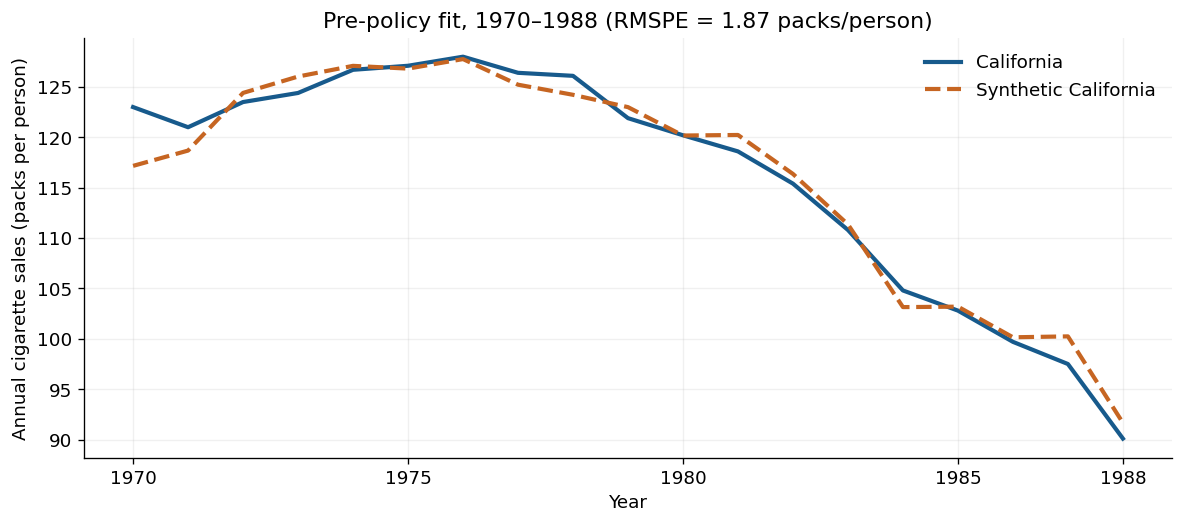

In [15]:
def rmspe(gaps):
    return float(np.sqrt(np.mean(np.square(gaps))))

pre_rmspe = rmspe(results.loc[PRE_YEARS, "gap"])
average_donor_gap = outcomes.loc[PRE_YEARS, TREATED] - outcomes.loc[PRE_YEARS, DONORS].mean(axis=1)
display(pd.DataFrame({"Pre-treatment RMSPE (packs/person)": {
    "Synthetic California": pre_rmspe,
    "Unweighted donor average": rmspe(average_donor_gap),
}}).round(2))

fig, ax = plt.subplots()
ax.plot(PRE_YEARS, results.loc[PRE_YEARS, "observed"], color=BLUE, lw=2.5, label="California")
ax.plot(PRE_YEARS, results.loc[PRE_YEARS, "synthetic"], color=ORANGE, ls="--", lw=2.5,
        label="Synthetic California")
ax.set(title=f"Pre-policy fit, 1970–1988 (RMSPE = {pre_rmspe:.2f} packs/person)",
       xlabel="Year", ylabel="Annual cigarette sales (packs per person)")
ax.set_xticks([1970, 1975, 1980, 1985, 1988])
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [16]:
# Compare predictor values in their original units.
X0, X1 = dataprep.make_covariate_mats()
balance = pd.DataFrame({"California": X1,
                        "Synthetic California": X0.dot(weights),
                        "Donor average": X0.mean(axis=1)})
balance.index = ["Log income, 1980–1988", "Price (cents), 1980–1988",
                 "Share age 15–24, 1980–1988", "Beer (gallons/person), 1984–1988",
                 "Cigarette sales, 1975", "Cigarette sales, 1980", "Cigarette sales, 1988"]
display(balance.round(3))

,California,Synthetic California,Donor average
"Log income, 1980–1988",10.077,9.874,9.829
"Price (cents), 1980–1988",89.422,89.322,87.266
"Share age 15–24, 1980–1988",0.174,0.174,0.173
"Beer (gallons/person), 1984–1988",24.280,23.643,23.655
"Cigarette sales, 1975",127.100,126.816,136.932
"Cigarette sales, 1980",120.200,120.176,138.089
"Cigarette sales, 1988",90.100,91.658,113.824


**Explain 3 — Assess fit before seeing the effect.** Use the graph and RMSPE to
describe the pre-policy fit. Identify any visible mismatch. Use the balance table
to name one characteristic matched well and one matched less closely.

A close fit supports the comparison. Causal interpretation still requires that
the donor states remain suitable after 1989: no important spillovers, no major
California-specific competing shock, and a stable relationship between California
and its synthetic control. See [Abadie (2021)](https://economics.mit.edu/sites/default/files/publications/jel.20191450.pdf).

## 5. Estimate and explain the policy effect

Now reveal the post-treatment observations. The weights remain fixed.

$$\widehat{\tau}_t=Y_{California,t}-Y_{Synthetic,t}.$$

A **negative gap** means California sold fewer packs per person than its estimated
no-policy counterfactual. A positive gap means more. Pre-treatment gaps measure
mismatch; only the post-treatment gaps are interpreted as estimated policy effects.

The percentage gap uses the **synthetic outcome as the denominator**. It answers
how much lower or higher sales were relative to what the model predicts without
the policy. It is not a percentage-point change in smoking prevalence.

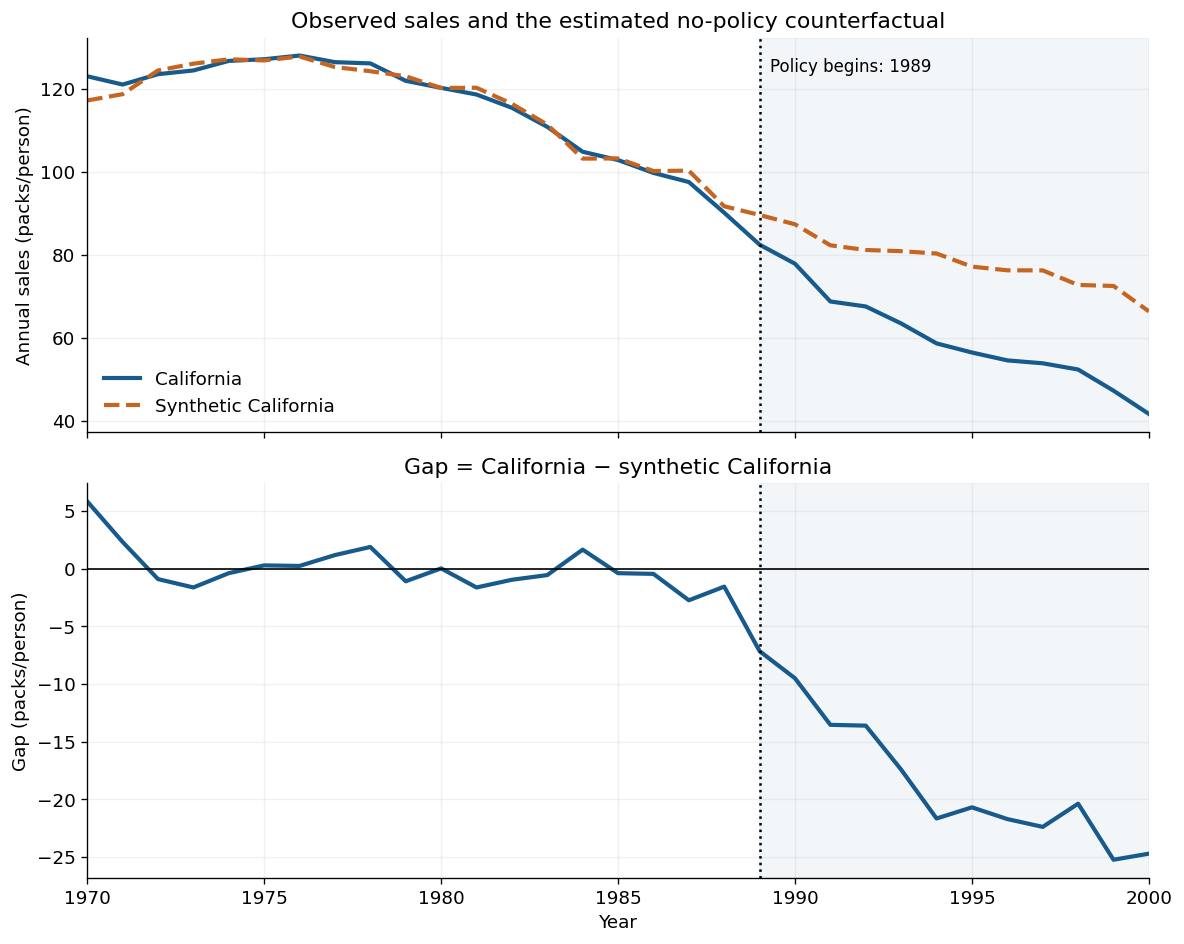

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
axes[0].plot(results.index, results["observed"], color=BLUE, lw=2.5, label="California")
axes[0].plot(results.index, results["synthetic"], color=ORANGE, ls="--", lw=2.5,
             label="Synthetic California")
axes[0].set(title="Observed sales and the estimated no-policy counterfactual",
            ylabel="Annual sales (packs/person)")
axes[0].legend(frameon=False)
axes[1].plot(results.index, results["gap"], color=BLUE, lw=2.5)
axes[1].axhline(0, color="black", lw=1)
axes[1].set(title="Gap = California − synthetic California",
            xlabel="Year", ylabel="Gap (packs/person)")
for ax in axes:
    ax.axvline(TREATMENT_YEAR, color="black", ls=":", lw=1.5)
    ax.axvspan(TREATMENT_YEAR, ALL_YEARS[-1], color=BLUE, alpha=0.05)
    ax.set_xlim(ALL_YEARS[0], ALL_YEARS[-1])
axes[0].text(TREATMENT_YEAR + 0.3, 0.95, "Policy begins: 1989",
             transform=axes[0].get_xaxis_transform(), va="top", fontsize=10)
plt.tight_layout()
plt.show()

In [18]:
# Change REPORT_YEAR to another post-policy year and explain what changes.
REPORT_YEAR = 2000
assert REPORT_YEAR in POST_YEARS
post = results.loc[POST_YEARS]
report = results.loc[REPORT_YEAR]
average_gap = post["gap"].mean()
percent_average_gap = 100 * average_gap / post["synthetic"].mean()

effect_table = results.loc[[1988, 1989, 1995, 2000],
                           ["observed", "synthetic", "gap", "percent_gap"]].copy()
effect_table.loc["1989–2000 annual average"] = [post["observed"].mean(),
    post["synthetic"].mean(), average_gap, percent_average_gap]
effect_table.columns = ["Observed packs/person", "Synthetic packs/person",
                        "Gap: packs/person", "Gap: % of synthetic"]
display(effect_table.round(2))

direction = "lower" if report["gap"] < 0 else "higher"
display(Markdown(
    f"**Worked interpretation for {REPORT_YEAR}:** California sold "
    f"{report['observed']:.1f} packs per person, compared with an estimated "
    f"{report['synthetic']:.1f} without Proposition 99. The estimated gap is "
    f"{report['gap']:.1f} packs per person, or {abs(report['percent_gap']):.1f}% "
    f"{direction} than the synthetic counterfactual. Interpreting this as a policy "
    "effect depends on the credibility of that counterfactual."
))
print(f"Average annual gap, 1989–2000: {average_gap:.2f} packs per person.")
print("The average-row percentage is the gap between period means divided by the synthetic mean;")
print("it is not the mean of the yearly percentage gaps.")

,Observed packs/person,Synthetic packs/person,Gap: packs/person,Gap: % of synthetic
year,,,,
1988,90.10,91.66,-1.56,-1.70
1989,82.40,89.55,-7.15,-7.99
1995,56.40,77.10,-20.70,-26.85
2000,41.60,66.32,-24.72,-37.27
1989–2000 annual average,60.35,78.52,-18.17,-23.14


**Worked interpretation for 2000:** California sold 41.6 packs per person, compared with an estimated 66.3 without Proposition 99. The estimated gap is -24.7 packs per person, or 37.3% lower than the synthetic counterfactual. Interpreting this as a policy effect depends on the credibility of that counterfactual.

Average annual gap, 1989–2000: -18.17 packs per person.
The average-row percentage is the gap between period means divided by the synthetic mean;
it is not the mean of the yearly percentage gaps.


**Explain 4 — Quantify the effect.** Report the estimated effect in 2000 and the
average annual effect over 1989–2000, with units. Describe whether the gap appears
immediately or develops over time. Then change `REPORT_YEAR` to 1995 and write a
one-sentence interpretation of that year's result.

Avoid saying “smoking fell by X percentage points,” “X packs were prevented in
total,” or “every resident smoked X fewer packs.” The outcome is a state-level
sales rate, and an annual average gap is not a cumulative count.

**Your response:**

_Write here._

## 6. Is California's gap unusual? Placebos in space

We now pretend that each donor state received the policy in 1989. For each one,
we fit a new synthetic control using the **same predictors, years, and fitting
procedure**. Its donors are the other original donor states. California is excluded
from these donor pools because its post-policy outcomes may be affected by treatment.

These are diagnostics using observational comparisons, not randomized experiments.
A placebo gap asks how much divergence this procedure produces for a state without
California's policy. One similar placebo is a reason to investigate, not an automatic
refutation of the result.

We use the **post/pre RMSPE ratio** to compare post-policy divergence with each
state's own pre-policy mismatch. Larger ratios mean more divergence relative to
baseline fit. The ratio uses squared gaps, so it does **not** tell us the effect's
direction; read the gap plot for that.

The loop refits all 38 donors and can take several minutes. While it runs, discuss
why a state with a terrible pre-policy fit would be an unhelpful placebo comparison.

In [ ]:
def fit_diagnostics(gap):
    pre = rmspe(gap.loc[PRE_YEARS])
    post = rmspe(gap.loc[POST_YEARS])
    if pre <= 1e-10:
        raise ValueError("A nearly zero pre-RMSPE makes the ratio unstable; inspect this fit.")
    return {"pre_rmspe": pre, "post_rmspe": post, "ratio": post / pre}

# Recreate these objects each time, so rerunning the cell does not append duplicates.
placebo_gaps = pd.DataFrame(index=ALL_YEARS)
diagnostics = {TREATED: fit_diagnostics(results["gap"])}
started = perf_counter()
for i, state in enumerate(DONORS, start=1):
    placebo_donors = [s for s in DONORS if s != state]
    placebo_model = fit_scm(make_dataprep(state, placebo_donors))
    placebo_weights = pd.Series(placebo_model.W, index=placebo_model.W_names)
    placebo_series = outcomes.loc[:, placebo_weights.index].dot(placebo_weights)
    placebo_gaps[state] = outcomes[state] - placebo_series
    diagnostics[state] = fit_diagnostics(placebo_gaps[state])
    if i % 5 == 0 or i == len(DONORS):
        print(f"Completed {i}/{len(DONORS)} placebo fits ({perf_counter()-started:.0f} seconds).")

diagnostics = pd.DataFrame.from_dict(diagnostics, orient="index")
diagnostics.index.name = "state"
assert placebo_gaps.shape == (len(ALL_YEARS), len(DONORS))
assert np.isfinite(placebo_gaps.to_numpy()).all()
assert np.isfinite(diagnostics.to_numpy()).all()

**Make the comparison set explicit.** We display placebo states whose pre-treatment
RMSPE is no more than **five times California's**, a rule set before inspecting the
placebo outcomes. This removes the worst-fitting comparisons; it is not a universal
validity threshold. We use exactly the same eligible states for both plots and the
main rank calculation, and also report the rank using all donors.

The **placebo rank fraction** is

$$\frac{1+\#\{\text{eligible placebo ratios at least as large as California's}\}}
{1+\#\{\text{eligible placebo states}\}}.$$

The 1 includes California itself, and ties count as at least as extreme. This
fraction describes California's rank in this comparison set. It is not the
probability that Proposition 99 had no effect, and it does not eliminate concerns
about confounding or spillovers. Formal randomization inference requires additional
assumptions about treatment assignment and comparability.

In [ ]:
eligible = diagnostics.loc[DONORS, "pre_rmspe"] <= FIT_MULTIPLE * diagnostics.loc[TREATED, "pre_rmspe"]
eligible_states = eligible.index[eligible].tolist()
excluded_states = eligible.index[~eligible].tolist()
california_ratio = diagnostics.loc[TREATED, "ratio"]

def rank_summary(states):
    extreme = int((diagnostics.loc[states, "ratio"] >= california_ratio).sum())
    return {"Placebo states": len(states), "Placebos at least as extreme": extreme,
            "Numerator (includes CA)": extreme + 1, "Denominator (includes CA)": len(states) + 1,
            "Rank fraction": (extreme + 1) / (len(states) + 1)}

rank_table = pd.DataFrame({
    f"Pre-RMSPE ≤ {FIT_MULTIPLE} × California": rank_summary(eligible_states),
    "All donor states": rank_summary(DONORS),
}).T
display(rank_table.round(3))
print(f"California post/pre RMSPE ratio: {california_ratio:.2f}")
print(f"Retained {len(eligible_states)} of {len(DONORS)} placebo states.")
print("Excluded for pre-treatment fit:", ", ".join(excluded_states) or "None")
display(diagnostics.loc[[TREATED] + eligible_states].sort_values("ratio", ascending=False).head(10).round(2))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.25, 1]})
for i, state in enumerate(eligible_states):
    axes[0].plot(placebo_gaps.index, placebo_gaps[state], color=GRAY, lw=0.9, alpha=0.65,
                 label="Eligible placebo states" if i == 0 else None)
axes[0].plot(results.index, results["gap"], color=BLUE, lw=2.6, label="California", zorder=10)
axes[0].axhline(0, color="black", lw=0.8)
axes[0].axvline(TREATMENT_YEAR, color="black", ls=":")
axes[0].set(title="Gaps among states with comparable pre-policy fit",
            xlabel="Year", ylabel="Observed − synthetic (packs/person)")
axes[0].legend(frameon=False, fontsize=9)

ranked = diagnostics.loc[[TREATED] + eligible_states].sort_values("ratio")
colors = [BLUE if state == TREATED else GRAY for state in ranked.index]
axes[1].scatter(ranked["ratio"], range(len(ranked)), c=colors, s=30)
axes[1].set_yticks(range(len(ranked)), ranked.index, fontsize=7)
axes[1].set(title="Post/pre RMSPE ratios: same comparison set",
            xlabel="Post-treatment RMSPE / pre-treatment RMSPE")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Explain 5 — Interpret the placebo evidence.** Does California's gap look unusual
relative to the eligible placebos? Report its rank fraction with the numerator and
denominator. Explain what that fraction describes and one thing it cannot establish.
Why do we inspect pre-policy fit before comparing post-policy gaps?


**Your response:**

_Write here._

## 7. Does one donor drive the conclusion?

Remove the donor with the largest baseline weight and **refit the model** using
the remaining donors. Renormalizing the old weights would not answer the same
question. Compare both the new pre-treatment fit and the estimated post-treatment
gap with the baseline.

This is a targeted sensitivity check. A stable result increases confidence in
this aspect of the design; it does not prove that every modeling choice is harmless.
If the effect changes but the new pre-treatment fit is much worse, both facts belong
in the explanation. We do not choose between specifications based on which effect
is larger.

Removed Utah, whose baseline weight was 37.2%.


,Pre-RMSPE (packs/person),"Average annual gap, 1989–2000",Gap in 2000 (packs/person)
Baseline,1.85,-17.92,-24.45
Without Utah,2.60,-17.53,-23.51


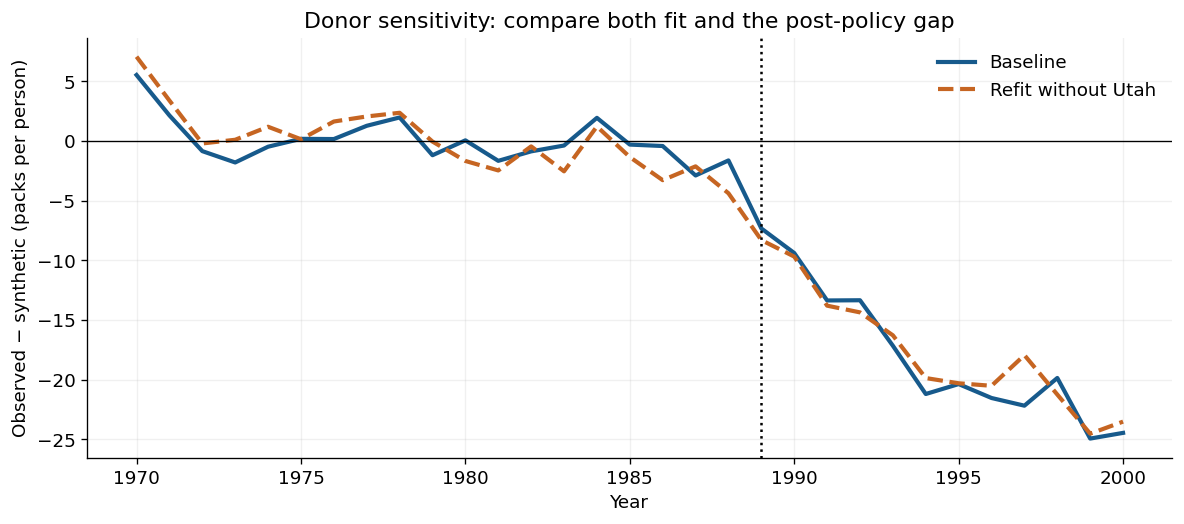

In [ ]:
donor_to_remove = largest_donor
remaining_donors = [s for s in DONORS if s != donor_to_remove]
sc_without = fit_scm(make_dataprep(TREATED, remaining_donors))
weights_without = pd.Series(sc_without.W, index=sc_without.W_names)
synthetic_without = outcomes.loc[:, weights_without.index].dot(weights_without)
gap_without = outcomes[TREATED] - synthetic_without

sensitivity = pd.DataFrame({
    "Baseline": {"Pre-RMSPE (packs/person)": pre_rmspe,
                 "Average annual gap, 1989–2000": average_gap,
                 "Gap in 2000 (packs/person)": results.loc[2000, "gap"]},
    f"Without {donor_to_remove}": {
        "Pre-RMSPE (packs/person)": rmspe(gap_without.loc[PRE_YEARS]),
        "Average annual gap, 1989–2000": gap_without.loc[POST_YEARS].mean(),
        "Gap in 2000 (packs/person)": gap_without.loc[2000]},
}).T
print(f"Removed {donor_to_remove}, whose baseline weight was {weights[donor_to_remove]:.1%}.")
display(sensitivity.round(2))

fig, ax = plt.subplots()
ax.plot(results.index, results["gap"], color=BLUE, lw=2.5, label="Baseline")
ax.plot(gap_without.index, gap_without, color=ORANGE, ls="--", lw=2.5,
        label=f"Refit without {donor_to_remove}")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(TREATMENT_YEAR, color="black", ls=":")
ax.set(title="Donor sensitivity: compare both fit and the post-policy gap",
       xlabel="Year", ylabel="Observed − synthetic (packs per person)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Explain 6 — Assess sensitivity.** Which donor was removed? Compare the direction
and magnitude of the estimated effect, and compare pre-policy fit. Write two
sentences describing whether this check strengthens, weakens, or leaves your
conclusion largely unchanged. Support your judgment with numbers.

**Your response:**

_Write here._